# Лабораторная работа №2. Задача кластеризации

**Студент:** Васютинский Вадим Александрович
**Вариант:** 8 (`lab2-08.xlsx`)

**Цель:** научиться применять модели кластеризации библиотеки scikit-learn к набору эмпирических данных.

**Результат:** число кластеров и обученная модель.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

RANDOM_STATE = 42
DATA_PATH = Path('..') / '..' / 'tasks' / 'lab2' / 'dataset' / 'lab2-08.xlsx'

## 1. Загрузка данных

In [2]:
data = pd.read_excel(DATA_PATH)
data.columns = ['x1', 'x2']
data.head()

,x1,x2
0,3.757193,-1.042462
1,1.788737,-1.772939
2,-2.608214,-1.925894
3,-1.871252,-0.173571
4,-3.728688,0.179285


In [3]:
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      1000 non-null   float64
 1   x2      1000 non-null   float64
dtypes: float64(2)
memory usage: 15.8 KB


,x1,x2
count,1000.000000,1000.000000
mean,-1.141497,-2.756044
std,4.446475,5.513910
min,-10.954978,-11.648055
25%,-4.067796,-7.252962
50%,0.250433,-2.627119
75%,2.484677,-0.963996
max,7.643615,12.613797


Файл содержит 1000 объектов с двумя числовыми признаками, пропусков нет. Оба признака измерены в одном масштабе (примерно от −12 до 13), поэтому нормализация не нужна.

## 2. Визуализация исходных данных

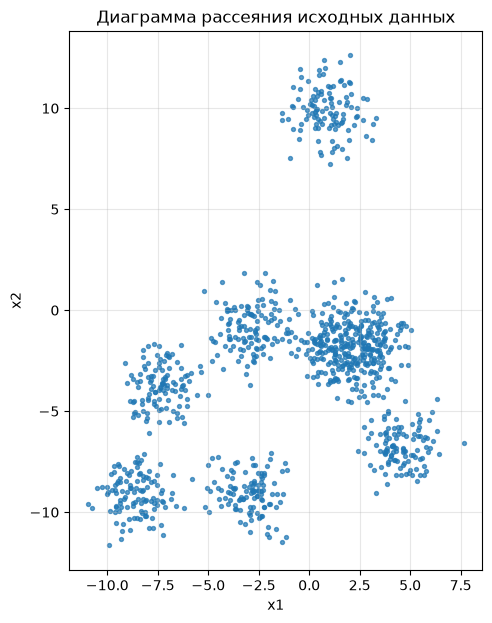

In [4]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(data['x1'], data['x2'], s=8, alpha=0.7)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Диаграмма рассеяния исходных данных')
ax.set_aspect('equal')
ax.grid(alpha=0.3)
plt.show()

На диаграмме видны компактные группы примерно круглой формы и близкого размера. Визуально групп 7; две из них (в центре, около точек (−3, −1) и (2, −2)) расположены близко и частично соприкасаются.

## 3. Оценка числа кластеров

Сначала разделим данные на обучающую (80 %) и тестовую (20 %) выборки. Число кластеров и модель
выбираются только по обучающей выборке, тестовая выборка нужна для проверки в п. 6.

In [5]:
X = data[['x1', 'x2']].to_numpy()
X_train, X_test = train_test_split(X, test_size=0.2, random_state=RANDOM_STATE)
print(f'Обучающая выборка: {len(X_train)}, тестовая: {len(X_test)}')

Обучающая выборка: 800, тестовая: 200


Для $k = 2, \dots, 10$ обучим KMeans и посчитаем:
- **инерцию** (сумму квадратов расстояний до центров), чтобы применить метод «локтя»;
- **коэффициент силуэта** (чем больше, тем лучше, максимум 1);
- **индекс Дэвиса–Болдина** (чем меньше, тем лучше);
- **индекс Калинского–Харабаша** (чем больше, тем лучше).

In [6]:
k_range = range(2, 11)
rows = []
for k in k_range:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train)
    rows.append({
        'k': k,
        'inertia': model.inertia_,
        'silhouette': silhouette_score(X_train, model.labels_),
        'davies_bouldin': davies_bouldin_score(X_train, model.labels_),
        'calinski_harabasz': calinski_harabasz_score(X_train, model.labels_),
    })
k_scores = pd.DataFrame(rows).set_index('k')
k_scores.round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,21231.075,0.471,0.814,709.642
3,9720.071,0.571,0.610,1245.951
4,6541.056,0.548,0.671,1361.702
5,4404.591,0.555,0.616,1611.151
6,2948.389,0.589,0.513,2001.524
7,1722.350,0.636,0.455,2945.930
8,1475.499,0.561,0.619,2962.539
9,1320.204,0.561,0.594,2905.845
10,1251.626,0.533,0.695,2725.812


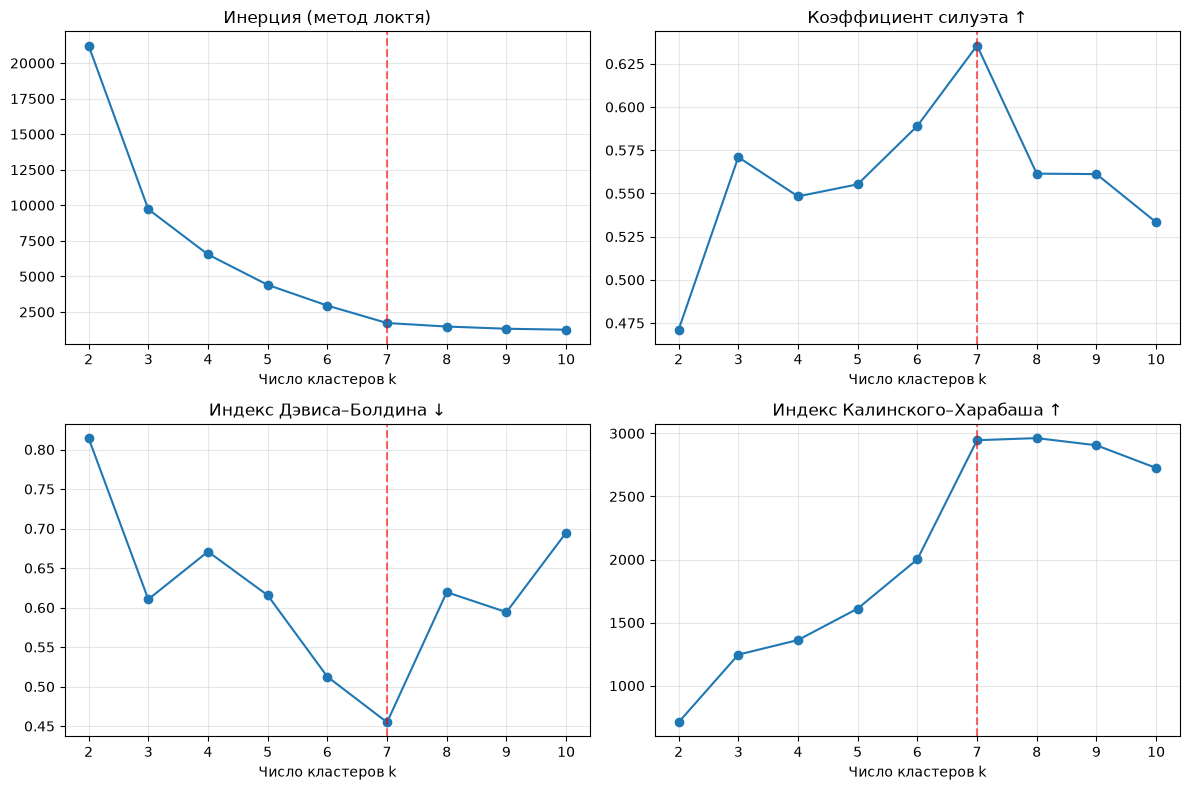

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
titles = {
    'inertia': 'Инерция (метод локтя)',
    'silhouette': 'Коэффициент силуэта ↑',
    'davies_bouldin': 'Индекс Дэвиса–Болдина ↓',
    'calinski_harabasz': 'Индекс Калинского–Харабаша ↑',
}
for ax, (column, title) in zip(axes.ravel(), titles.items()):
    ax.plot(k_scores.index, k_scores[column], marker='o')
    ax.axvline(7, color='red', linestyle='--', alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel('Число кластеров k')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
print('k по максимуму силуэта:            ', k_scores['silhouette'].idxmax())
print('k по минимуму Дэвиса–Болдина:     ', k_scores['davies_bouldin'].idxmin())
print('k по максимуму Калинского–Харабаша:', k_scores['calinski_harabasz'].idxmax())

k по максимуму силуэта:             7
k по минимуму Дэвиса–Болдина:      7
k по максимуму Калинского–Харабаша: 8


Для сравнения посчитаем информационный критерий BIC для гауссовой смеси: он оценивает, сколько
нормальных компонент лучше всего описывают данные с учётом штрафа за число параметров.

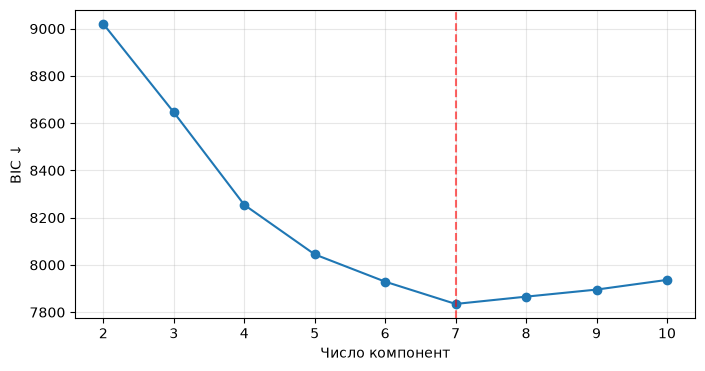

k по минимуму BIC: 7


In [9]:
bic = pd.Series(
    {k: GaussianMixture(n_components=k, n_init=5, random_state=RANDOM_STATE).fit(X_train).bic(X_train)
     for k in k_range},
    name='BIC',
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(bic.index, bic.values, marker='o')
ax.axvline(7, color='red', linestyle='--', alpha=0.6)
ax.set_xlabel('Число компонент')
ax.set_ylabel('BIC ↓')
ax.grid(alpha=0.3)
plt.show()
print('k по минимуму BIC:', bic.idxmin())

На графике инерции после $k = 7$ виден «локоть», а коэффициент силуэта, индекс Дэвиса–Болдина и BIC
достигают оптимума именно при $k = 7$. Индекс Калинского–Харабаша формально максимален при $k = 8$, но
отличается от значения при $k = 7$ всего на ~0.5 %, то есть фактически выходит на плато начиная с $k = 7$.
При $k = 8$ силуэт заметно падает (0.64 → 0.56): восьмой кластер получается разрезанием одной из групп пополам.
Вместе с визуальной оценкой это даёт **число кластеров: 7.**

## 4. Выбор модели кластеризации

Кластеры компактные, выпуклые, примерно круглые и с близким разбросом, шум и выбросы почти отсутствуют.
Для таких данных хорошо подходит **KMeans**: он ищет $k$ центров, минимизируя внутрикластерный разброс,
и умеет относить новые точки к ближайшему центру (метод `predict`), что нужно для проверки на тестовой выборке.

В качестве альтернативы рассмотрим **гауссову смесь** (`GaussianMixture`): она допускает эллиптические кластеры
разного размера и тоже умеет предсказывать кластер для новых точек.
Методы на основе плотности (DBSCAN) здесь менее удобны: две центральные группы соприкасаются,
и DBSCAN легко сольёт их в одну, к тому же он не умеет предсказывать кластер для новых точек.

## 5. Обучение модели на обучающей выборке

In [10]:
N_CLUSTERS = 7

kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE).fit(X_train)
gmm = GaussianMixture(n_components=N_CLUSTERS, n_init=5, random_state=RANDOM_STATE).fit(X_train)

centers = pd.DataFrame(kmeans.cluster_centers_, columns=['x1', 'x2'])
centers['size'] = np.bincount(kmeans.labels_)
centers.round(3)

,x1,x2,size
0,4.466,-6.756,91
1,2.134,-1.777,251
2,-8.643,-9.153,86
3,0.909,9.889,88
4,-7.388,-3.702,88
5,-3.030,-9.081,97
6,-2.686,-0.920,99


Шесть кластеров содержат примерно по 90–100 точек, а центральный кластер около (2.1, −1.8) примерно в 2.5 раза больше.
При этом его разброс лишь немного превышает разброс остальных групп, то есть это одна более плотная группа,
а не две слившиеся: при $k = 8$ ни KMeans, ни гауссова смесь не выделяют внутри неё отдельной структуры.
Возможно, в данных здесь совпадают несколько источников, но по геометрии точек различить их нельзя.

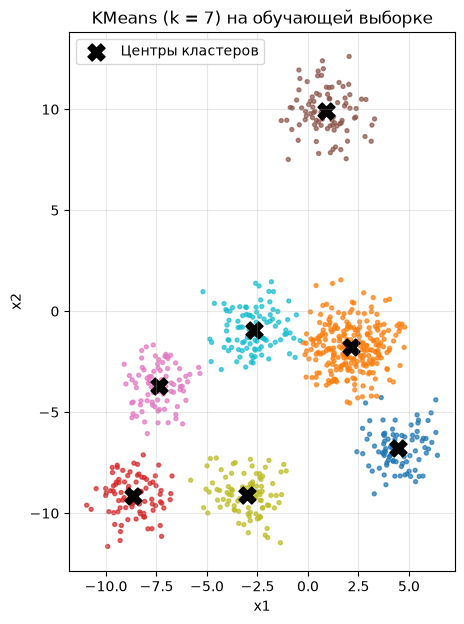

In [11]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X_train[:, 0], X_train[:, 1], c=kmeans.labels_, cmap='tab10', s=8, alpha=0.7)
ax.scatter(*kmeans.cluster_centers_.T, c='black', marker='X', s=150, label='Центры кластеров')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('KMeans (k = 7) на обучающей выборке')
ax.set_aspect('equal')
ax.legend()
ax.grid(alpha=0.3)
plt.show()